In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score

In [5]:
#importation des donnees
data=pd.read_csv("Boston.csv",index_col=0)  
data.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 1 to 506
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  black    506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


In [9]:
# Renommage des colonnes 
data.columns = ["Taux_criminalite", "Prop_terrains_resid", "Prop_acres_indus", "Bordure_riviere", "Concentration_NO2",
                "Nb_pieces_logement", "Prop_log_construits_av1940", "Dist_ponderees_emploi", "Accessibilite_autoroute",
                "Taux_impot_foncier", "Ratio_eleve_prof", "Prop_noirs_ville", "Pourcentage_pop_inf", "Valeur_med_logement"]



# Affichage des 5 premières lignes de la base de données avec les noms de colonnes renommés
data.head()

,Taux_criminalite,Prop_terrains_resid,Prop_acres_indus,Bordure_riviere,Concentration_NO2,Nb_pieces_logement,Prop_log_construits_av1940,Dist_ponderees_emploi,Accessibilite_autoroute,Taux_impot_foncier,Ratio_eleve_prof,Prop_noirs_ville,Pourcentage_pop_inf,Valeur_med_logement
1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


## Description des variables du dataset Boston Housing

1. **Taux_criminalite :** Taux de criminalité par habitant par ville.
2. **Prop_terrains_resid :** Proportion de terrains résidentiels zonés pour des lots de plus de 25 000 pieds carrés.
3. **Prop_acres_indus :** Proportion d'acres industriels non commerciaux par ville.
4. **Bordure_riviere :** Variable fictive Charles River (= 1 si le tronçon borde la rivière ; 0 sinon).
5. **Concentration_NO2 :** Concentration de dioxyde d'azote (parties par 10 millions).
6. **Nb_pieces_logement :** Nombre moyen de pièces par logement.
7. **Prop_log_construits_av1940 :** Proportion de logements occupés par leur propriétaire construits avant 1940.
8. **Dist_ponderees_emploi :** Distances pondérées aux cinq centres d'emploi de Boston.
9. **Accessibilite_autoroute :** Indice d'accessibilité aux autoroutes radiales.
10. **Taux_impot_foncier :** Taux d'impôt foncier sur la valeur totale de la propriété.
11. **Ratio_eleve_prof :** Ratio élève-professeur par ville.
12. **Prop_noirs_ville :** Proportion de la population noire par ville.
13. **Pourcentage_pop_inf :** Pourcentage de statut inférieur de la population.
14. **Valeur_med_logement :** Valeur médiane des maisons occupées par leur propriétaire, en milliers de dollars.

In [10]:
# valeurs manquantes

data.isnull().sum()

Taux_criminalite              0
Prop_terrains_resid           0
Prop_acres_indus              0
Bordure_riviere               0
Concentration_NO2             0
Nb_pieces_logement            0
Prop_log_construits_av1940    0
Dist_ponderees_emploi         0
Accessibilite_autoroute       0
Taux_impot_foncier            0
Ratio_eleve_prof              0
Prop_noirs_ville              0
Pourcentage_pop_inf           0
Valeur_med_logement           0
dtype: int64

# 1.1 Analyse de la base globale

In [11]:
# resume statistique des variables
data.describe()

,Taux_criminalite,Prop_terrains_resid,Prop_acres_indus,Bordure_riviere,Concentration_NO2,Nb_pieces_logement,Prop_log_construits_av1940,Dist_ponderees_emploi,Accessibilite_autoroute,Taux_impot_foncier,Ratio_eleve_prof,Prop_noirs_ville,Pourcentage_pop_inf,Valeur_med_logement
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


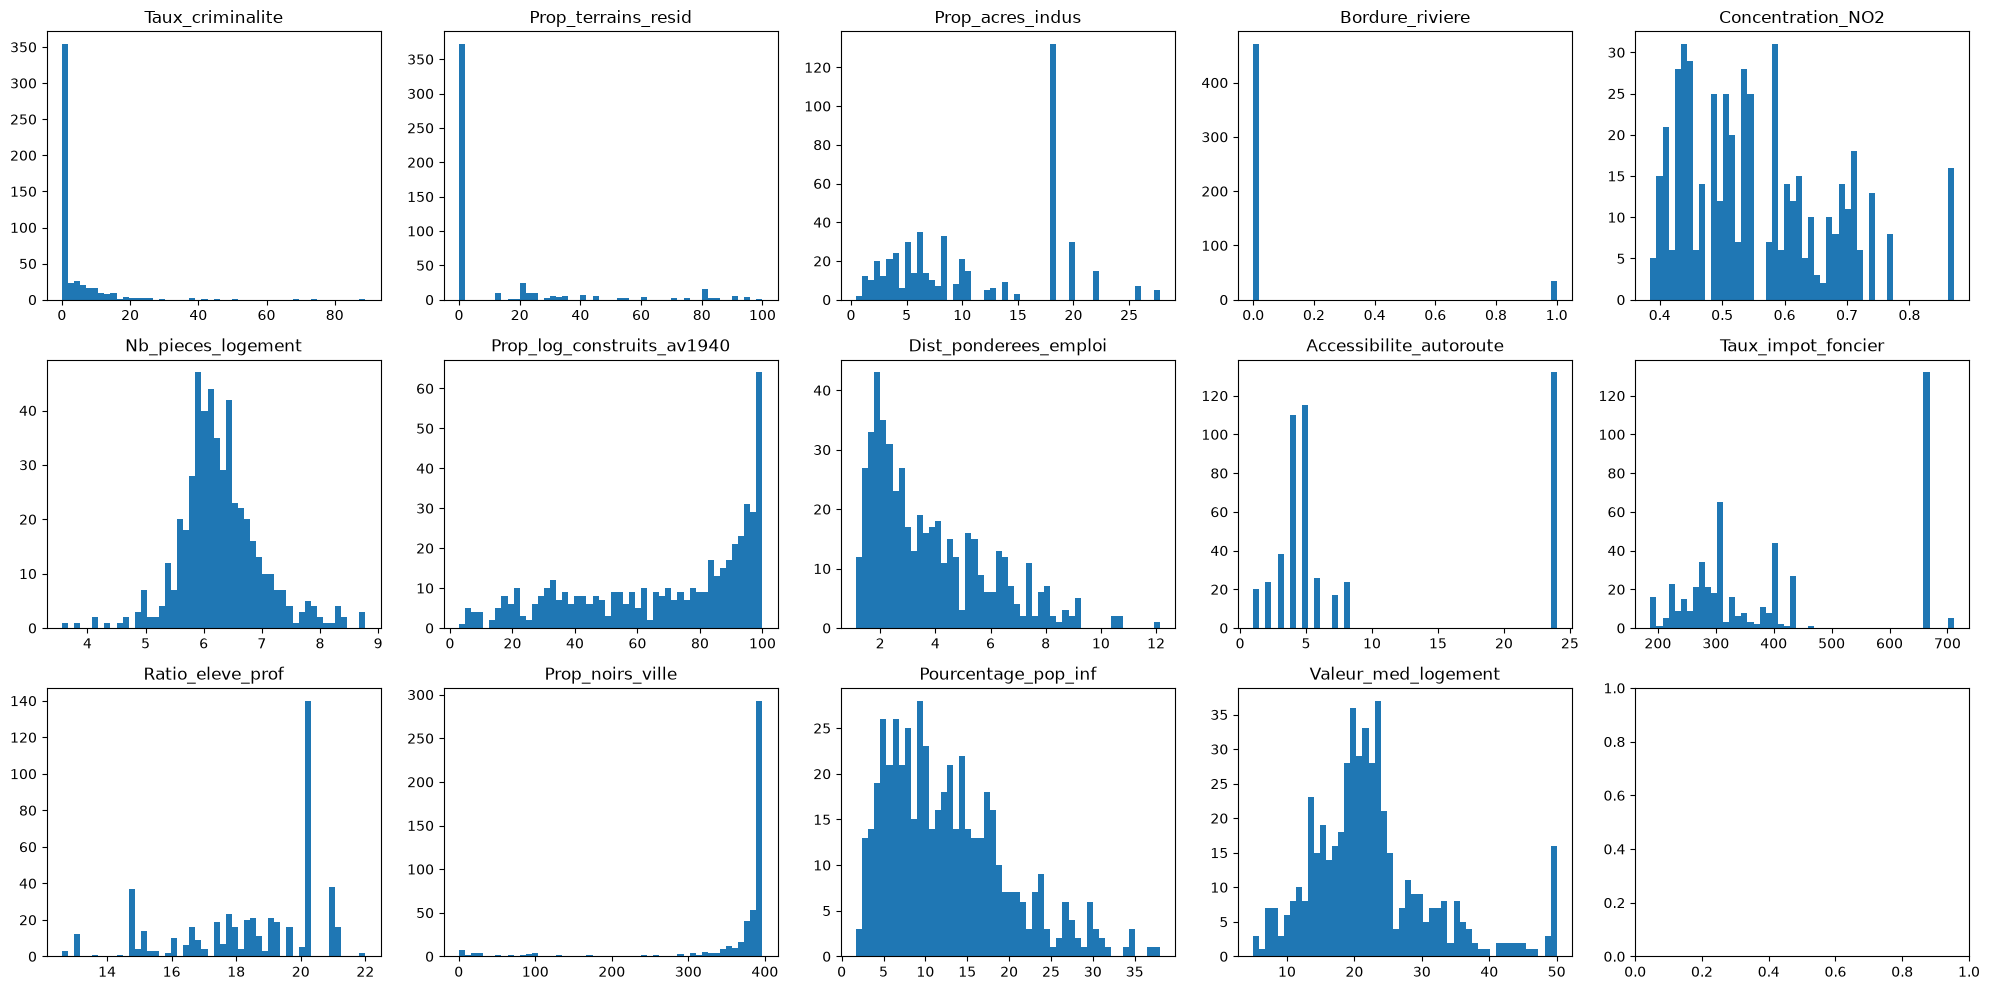

In [15]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(3, 5, figsize=(20, 10))

# Transformer la matrice d'axes en tableau 1D
axs = axs.ravel()

for i, column in enumerate(data.columns):
    axs[i].hist(data[column], bins=50)
    axs[i].set_title(column)

# Ajuster l'espacement entre les graphiques
plt.tight_layout()

plt.show()  